# AI Object Counting (Weeks 1 and 2)
**Week 1:** detection and counting with pretrained YOLOv8.
**Week 2:** Gradio interface, CSV export, input validation.

**Tip:** Runtime > Change runtime type > T4 GPU

## Week 1: Setup and core detection

In [1]:
!pip install ultralytics gradio -q

In [2]:
from ultralytics import YOLO
import cv2, os, glob, csv
from datetime import datetime
from collections import Counter
import matplotlib.pyplot as plt

model = YOLO("yolov8s.pt")   # pretrained on COCO (80 classes)
ALL_CLASSES = list(model.names.values())
print(len(ALL_CLASSES), "classes available")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
80 classes available


### Add test images\nUpload your permitted test images (note their sources). They are saved in `test_images/`.

In [5]:
from google.colab import files
os.makedirs("test_images", exist_ok=True)
uploaded = files.upload()
for name in uploaded:
    os.replace(name, os.path.join("test_images", name))
print(os.listdir("test_images"))

Saving bang street.webp to bang street.webp
Saving beetles street.webp to beetles street.webp
Saving cali street.webp to cali street.webp
Saving cambodia.jpg to cambodia.jpg
Saving china street.webp to china street.webp
Saving den street.webp to den street.webp
Saving gaza street.webp to gaza street.webp
Saving hong kong street.webp to hong kong street.webp
Saving iceland street.webp to iceland street.webp
Saving ind street.webp to ind street.webp
Saving iran street.webp to iran street.webp
Saving jordan street.webp to jordan street.webp
Saving london street.webp to london street.webp
Saving malay street.webp to malay street.webp
Saving nigeria street.webp to nigeria street.webp
Saving pak street 2.jpg to pak street 2.jpg
Saving pak street.webp to pak street.webp
Saving spain street.jpg to spain street.jpg
Saving sri street.webp to sri street.webp
Saving syria street.jpg to syria street.jpg
['pak street 2.jpg', 'pak street.webp', 'iceland street.webp', 'malay street.webp', 'london stre

### Count function\nFilters by class names, confidence, and image size. Returns counts, total, and the annotated image.

In [6]:
def count_objects(image_path, target_classes=None, conf=0.25, imgsz=640):
    class_ids = None
    if target_classes:
        name_to_id = {v: k for k, v in model.names.items()}
        class_ids = [name_to_id[c] for c in target_classes]

    result = model(image_path, conf=conf, imgsz=imgsz, classes=class_ids, verbose=False)[0]
    labels = [model.names[int(b.cls)] for b in result.boxes]
    counts = Counter(labels)
    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)  # boxes, labels, confidence
    return dict(counts), sum(counts.values()), annotated

### Test on one image

Per-class: {'person': 13} | Total: 13


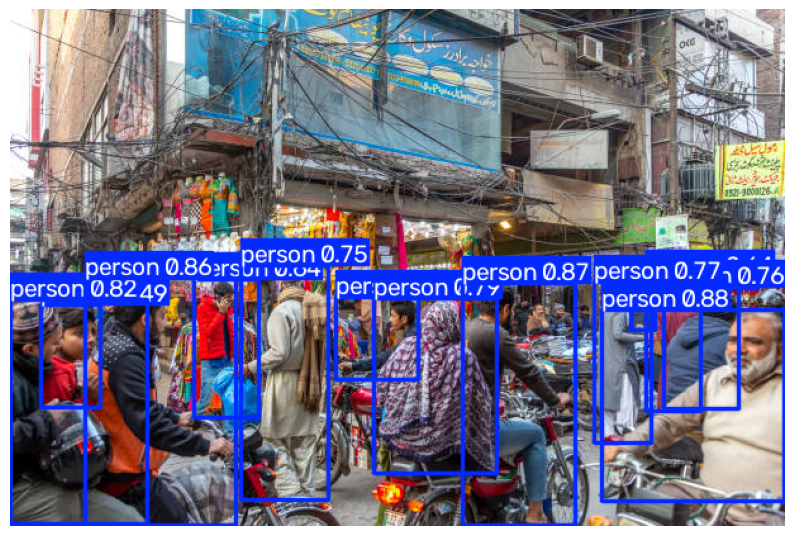

In [7]:
path = glob.glob("test_images/*")[0]
counts, total, img = count_objects(path, target_classes=["person", "car"], conf=0.25)
print("Per-class:", counts, "| Total:", total)
plt.figure(figsize=(10, 7)); plt.imshow(img); plt.axis("off"); plt.show()

## Week 2: Interface, export, and validation

### Where to save the results CSV\nTries Google Drive so the log survives a session reset. Falls back to the Colab folder if Drive is not mounted.

In [8]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    LOG_DIR = "/content/drive/MyDrive/object_counting"
except Exception as e:
    print("Drive not mounted, saving locally:", e)
    LOG_DIR = "/content/object_counting"
os.makedirs(LOG_DIR, exist_ok=True)
LOG_PATH = os.path.join(LOG_DIR, "results_log.csv")
print("Results will be saved to:", LOG_PATH)

Mounted at /content/drive
Results will be saved to: /content/drive/MyDrive/object_counting/results_log.csv


### Logging function\nAppends one row per run: input filename, timestamp, settings, total, and per-class counts.

In [9]:
def log_result(filename, conf, imgsz, counts, total):
    new_file = not os.path.exists(LOG_PATH)
    with open(LOG_PATH, "a", newline="") as f:
        w = csv.writer(f)
        if new_file:
            w.writerow(["input_filename", "timestamp", "confidence", "image_size", "total_count", "per_class_counts"])
        w.writerow([filename, datetime.now().strftime("%Y-%m-%d %H:%M:%S"), conf, imgsz, total,
                    "; ".join(f"{k}: {v}" for k, v in counts.items())])

### Gradio app\nUpload an image, choose classes, set confidence, and view the annotated result with counts. Invalid input shows a clear error message.

In [11]:
!pip install -q ultralytics fastapi uvicorn python-multipart pyngrok

In [12]:
import os, csv, threading
from google.colab import drive
from ultralytics import YOLO

try:
    drive.mount("/content/drive")
    LOG_DIR = "/content/drive/MyDrive/object_counting"
except Exception as e:
    print("Drive not mounted, saving locally:", e)
    LOG_DIR = "/content/object_counting"
os.makedirs(LOG_DIR, exist_ok=True)
LOG_PATH = os.path.join(LOG_DIR, "results_log.csv")
LOG_LOCK = threading.Lock()

model = YOLO("yolov8s.pt")
ALL_CLASSES = list(model.names.values())
NAME_TO_ID = {v: k for k, v in model.names.items()}
print(len(ALL_CLASSES), "classes | log file:", LOG_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
80 classes | log file: /content/drive/MyDrive/object_counting/results_log.csv


In [22]:
%%writefile index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>AI Object Counting</title>
<style>
:root{--bg:#080d1a;--panel:rgba(255,255,255,.045);--line:rgba(255,255,255,.09);--text:#e6ebf5;--muted:#8794ab;--acc:#5b8cff;--acc2:#2dd4bf;--danger:#f43f5e;--ok:#22c55e}
*{box-sizing:border-box}
html,body{height:100%}
body{margin:0;font-family:-apple-system,"Segoe UI",Roboto,Helvetica,Arial,sans-serif;background:var(--bg);color:var(--text);display:flex;flex-direction:column;overflow:hidden;font-size:14px}

.bg{position:fixed;inset:0;z-index:-1;overflow:hidden}
.blob{position:absolute;border-radius:50%;filter:blur(110px);opacity:.28;animation:float 22s ease-in-out infinite}
.b1{width:480px;height:480px;background:#3b5bdb;top:-160px;left:-120px}
.b2{width:420px;height:420px;background:#0d9488;bottom:-160px;right:-80px;animation-delay:-9s}
@keyframes float{0%,100%{transform:translate(0,0)}50%{transform:translate(50px,40px)}}

header{flex:none;display:flex;align-items:center;justify-content:space-between;gap:16px;padding:12px 24px;border-bottom:1px solid var(--line);background:rgba(8,13,26,.6);backdrop-filter:blur(10px)}
.brand{display:flex;align-items:center;gap:12px}
.logo{width:34px;height:34px;border-radius:9px;background:linear-gradient(135deg,var(--acc),var(--acc2));display:grid;place-items:center}
.logo svg{width:19px;height:19px;stroke:#fff}
.brand h1{margin:0;font-size:16px;font-weight:700;letter-spacing:-.2px}
.brand p{margin:2px 0 0;font-size:12px;color:var(--muted)}
.status{display:flex;align-items:center;gap:8px;font-size:12px;color:var(--muted);padding:6px 12px;border:1px solid var(--line);border-radius:999px;background:var(--panel);white-space:nowrap}
.dot{width:8px;height:8px;border-radius:50%;background:#64748b}
.dot.on{background:var(--ok);animation:pulse 1.8s infinite}
@keyframes pulse{0%{box-shadow:0 0 0 0 rgba(34,197,94,.55)}70%{box-shadow:0 0 0 8px rgba(34,197,94,0)}100%{box-shadow:0 0 0 0 rgba(34,197,94,0)}}

main{flex:1;min-height:0;display:grid;grid-template-columns:370px 1fr;gap:16px;padding:16px 24px 8px}
.left,.right{display:flex;flex-direction:column;gap:16px;min-height:0;min-width:0}
.card{background:var(--panel);border:1px solid var(--line);border-radius:14px;padding:16px;display:flex;flex-direction:column;min-height:0;backdrop-filter:blur(12px);animation:rise .5s both;transition:border-color .25s}
.card:hover{border-color:rgba(91,140,255,.4)}
@keyframes rise{from{opacity:0;transform:translateY(12px)}to{opacity:1;transform:none}}
.ch{display:flex;align-items:center;justify-content:space-between;margin-bottom:12px;flex:none}
.ch h2{margin:0;font-size:11px;font-weight:700;text-transform:uppercase;letter-spacing:1.2px;color:#9db4ff}
.step{display:inline-grid;place-items:center;width:18px;height:18px;border-radius:50%;background:rgba(91,140,255,.2);color:#9db4ff;font-size:10px;margin-right:8px;letter-spacing:0}

/* upload */
.up{flex:none}
.dz{position:relative;height:118px;border:1.5px dashed rgba(157,180,255,.4);border-radius:12px;display:flex;align-items:center;justify-content:center;text-align:center;cursor:pointer;color:var(--muted);transition:.2s;overflow:hidden}
.dz:hover,.dz.over{border-color:var(--acc2);background:rgba(45,212,191,.06);color:#fff}
.dz img{display:none;position:absolute;inset:0;width:100%;height:100%;object-fit:cover}
.dzin{position:relative;display:flex;flex-direction:column;align-items:center;gap:6px;padding:8px;font-size:13px}
.dzin svg{width:26px;height:26px;stroke:currentColor;animation:bob 2.8s ease-in-out infinite}
@keyframes bob{0%,100%{transform:translateY(0)}50%{transform:translateY(-4px)}}
.dz.has{border-style:solid;border-color:var(--line)}
.dz.has img{display:block}
.dz.has .dzin{position:absolute;left:0;right:0;bottom:0;flex-direction:row;justify-content:space-between;padding:8px 12px;background:linear-gradient(transparent,rgba(0,0,0,.8));color:#fff;font-size:12px}
.dz.has .dzin svg{display:none}
.dz.has .dzin .hint{opacity:.7}
.scan{display:none;position:absolute;left:0;right:0;height:3px;background:linear-gradient(90deg,transparent,var(--acc2),transparent);box-shadow:0 0 16px 5px rgba(45,212,191,.55);animation:scan 1.5s ease-in-out infinite}
.dz.scanning .scan{display:block}
.dz.scanning::after{content:"";position:absolute;inset:0;background:rgba(45,212,191,.07)}
@keyframes scan{0%{top:0}50%{top:calc(100% - 3px)}100%{top:0}}

/* settings */
.set{flex:1}
.lbl{font-size:12px;font-weight:600;margin:0 0 6px;display:flex;justify-content:space-between;color:var(--text);flex:none}
.lbl span{font-weight:400;color:var(--muted)}
input[type=text],select{width:100%;padding:8px 10px;border:1px solid var(--line);border-radius:8px;font-size:13px;background:rgba(0,0,0,.3);color:var(--text);outline:none;transition:.2s}
input[type=text]:focus,select:focus{border-color:var(--acc);box-shadow:0 0 0 3px rgba(91,140,255,.22)}
select option{background:#0f172a}
.chips{display:flex;gap:6px;margin:8px 0;flex:none}
.chip{border:1px solid var(--line);background:rgba(255,255,255,.04);border-radius:999px;padding:3px 11px;font-size:12px;cursor:pointer;transition:.2s;color:var(--text)}
.chip:hover{border-color:var(--acc2);color:var(--acc2)}
#classList{flex:1;min-height:70px;overflow:auto;border:1px solid var(--line);border-radius:8px;padding:4px;background:rgba(0,0,0,.2)}
.cls{display:flex;align-items:center;gap:8px;padding:4px 8px;font-size:13px;cursor:pointer;border-radius:6px;transition:.15s}
.cls:hover{background:rgba(255,255,255,.07)}
.cls input{accent-color:var(--acc)}
.ctl{flex:none;margin-top:12px}
input[type=range]{width:100%;accent-color:var(--acc2);margin:2px 0}
.row{display:flex;justify-content:space-between;align-items:center;font-size:11px;color:var(--muted)}
.row b{color:var(--acc2);font-size:13px}
button.go{flex:none;position:relative;width:100%;margin-top:14px;padding:12px;border:0;border-radius:10px;background:linear-gradient(90deg,var(--acc),var(--acc2),var(--acc));background-size:200% 100%;color:#fff;font-size:14px;font-weight:700;cursor:pointer;animation:shimmer 5s linear infinite;box-shadow:0 6px 22px rgba(91,140,255,.35);transition:transform .2s,box-shadow .2s}
button.go:hover{transform:translateY(-2px);box-shadow:0 10px 28px rgba(45,212,191,.4)}
button.go:active{transform:scale(.98)}
button.go:disabled{cursor:wait;opacity:.85}
@keyframes shimmer{to{background-position:200% 0}}
.spin{display:inline-block;width:13px;height:13px;border:2px solid rgba(255,255,255,.4);border-top-color:#fff;border-radius:50%;margin-right:8px;vertical-align:-2px;animation:rot .7s linear infinite}
@keyframes rot{to{transform:rotate(360deg)}}

/* result */
.res{flex:1}
.empty{flex:1;display:flex;flex-direction:column;align-items:center;justify-content:center;color:var(--muted);font-size:13px;gap:10px;text-align:center}
.empty svg{width:42px;height:42px;stroke:#5a6a86;animation:bob 3s ease-in-out infinite}
#result{display:none;flex:1;min-height:0;grid-template-columns:1fr 280px;gap:16px}
.stage{min-height:0;min-width:0;background:rgba(0,0,0,.28);border:1px solid var(--line);border-radius:10px;overflow:hidden}
#resImg{display:block;width:100%;height:100%;object-fit:contain}
#resImg.reveal{animation:reveal .9s ease-out both}
@keyframes reveal{from{clip-path:inset(0 100% 0 0);filter:brightness(1.6)}to{clip-path:inset(0 0 0 0);filter:none}}
.stats{display:flex;flex-direction:column;min-height:0}
.total{flex:none;display:flex;align-items:baseline;gap:10px}
.total b{font-size:56px;line-height:1;font-weight:800;background:linear-gradient(90deg,var(--acc),var(--acc2));-webkit-background-clip:text;background-clip:text;color:transparent}
.total span{color:var(--muted);font-size:13px}
.meta{flex:none;font-size:11px;color:var(--muted);margin:8px 0 12px;line-height:1.5;word-break:break-all}
.cards{flex:1;min-height:0;overflow:auto;display:flex;flex-direction:column;gap:8px;padding-right:4px}
.cc{flex:none;background:rgba(255,255,255,.045);border:1px solid var(--line);border-radius:9px;padding:9px 12px;opacity:0;animation:pop .45s cubic-bezier(.2,1.3,.4,1) forwards;transition:transform .2s}
.cc:hover{transform:translateX(3px)}
.cc .top{display:flex;justify-content:space-between;align-items:baseline}
.cc span{font-size:13px;text-transform:capitalize}
.cc b{font-size:18px;font-weight:700}
.bar{height:4px;border-radius:99px;background:rgba(255,255,255,.09);margin-top:7px;overflow:hidden}
.bar i{display:block;height:100%;width:0;border-radius:99px;transition:width 1s cubic-bezier(.2,.8,.2,1)}
@keyframes pop{from{opacity:0;transform:translateX(16px)}to{opacity:1;transform:none}}

/* history */
.hist{flex:none;height:205px}
.tbl{flex:1;min-height:0;overflow:auto}
table{width:100%;border-collapse:collapse;font-size:12px}
th,td{text-align:left;padding:7px 8px;border-bottom:1px solid var(--line);white-space:nowrap}
td:last-child{white-space:normal}
th{position:sticky;top:0;background:#0d1426;color:var(--muted);font-weight:600;font-size:10px;text-transform:uppercase;letter-spacing:.8px}
tbody tr{animation:slide .35s both}
tbody tr:hover{background:rgba(255,255,255,.04)}
tbody tr.fresh{background:rgba(45,212,191,.13)}
@keyframes slide{from{opacity:0;transform:translateX(-10px)}to{opacity:1;transform:none}}
a.dl{display:inline-flex;align-items:center;gap:6px;font-size:12px;color:var(--acc2);text-decoration:none;font-weight:600;padding:4px 10px;border:1px solid rgba(45,212,191,.35);border-radius:8px;transition:.2s}
a.dl:hover{background:rgba(45,212,191,.12)}
a.dl svg{width:13px;height:13px;stroke:currentColor}

footer{flex:none;padding:4px 24px 10px;font-size:11px;color:var(--muted)}
.toast{position:fixed;right:22px;bottom:22px;padding:12px 16px;border-radius:10px;color:#fff;font-size:13px;opacity:0;transform:translateY(14px);transition:.3s;pointer-events:none;max-width:340px;box-shadow:0 10px 30px rgba(0,0,0,.4);z-index:10}
.toast.show{opacity:1;transform:none}
.toast.err{background:linear-gradient(90deg,#be123c,var(--danger))}
.toast.ok{background:linear-gradient(90deg,#15803d,var(--ok))}
svg{fill:none;stroke-width:1.8;stroke-linecap:round;stroke-linejoin:round}

/* small screens: normal scrolling page */
@media(max-width:980px),(max-height:640px){
  body{height:auto;overflow:auto}
  main{grid-template-columns:1fr}
  #classList{min-height:150px;max-height:200px}
  #result{grid-template-columns:1fr}
  .stage{height:300px}
  .cards{max-height:220px}
  .hist{height:260px}
}
@media (prefers-reduced-motion:reduce){*{animation:none!important;transition:none!important}.cc{opacity:1}}
</style>
</head>
<body>
<div class="bg"><div class="blob b1"></div><div class="blob b2"></div></div>

<header>
  <div class="brand">
    <div class="logo"><svg viewBox="0 0 24 24"><path d="M4 8V6a2 2 0 0 1 2-2h2M16 4h2a2 2 0 0 1 2 2v2M20 16v2a2 2 0 0 1-2 2h-2M8 20H6a2 2 0 0 1-2-2v-2"/><circle cx="12" cy="12" r="3"/></svg></div>
    <div>
      <h1>AI Object Counting</h1>
      <p>Pretrained YOLOv8 detection with per-class counts, confidence filtering and CSV export</p>
    </div>
  </div>
  <div class="status"><span class="dot" id="dot"></span><span id="statusText">Connecting...</span></div>
</header>

<main>
  <div class="left">
    <div class="card up">
      <div class="ch"><h2><span class="step">1</span>Upload image</h2></div>
      <div class="dz" id="dz">
        <img id="preview" alt="Preview">
        <div class="dzin">
          <svg viewBox="0 0 24 24"><path d="M12 16V4M7 9l5-5 5 5M4 16v2a2 2 0 0 0 2 2h12a2 2 0 0 0 2-2v-2"/></svg>
          <span id="dzText">Drag and drop an image, or click to browse</span>
          <span class="hint" id="dzHint" style="display:none">Click to change</span>
        </div>
        <div class="scan"></div>
      </div>
      <input type="file" id="fileInput" accept=".jpg,.jpeg,.png,.bmp,.webp" hidden>
    </div>

    <div class="card set">
      <div class="ch"><h2><span class="step">2</span>Settings</h2></div>
      <div class="lbl">Classes to count <span id="selCount"></span></div>
      <input type="text" id="filter" placeholder="Search classes...">
      <div class="chips">
        <span class="chip" onclick="preset(['person'])">People</span>
        <span class="chip" onclick="preset(['car','truck','bus','motorcycle','bicycle'])">Vehicles</span>
        <span class="chip" onclick="preset([])">Clear</span>
      </div>
      <div id="classList"></div>
      <div class="ctl">
        <div class="lbl">Confidence threshold</div>
        <input type="range" id="conf" min="0.05" max="0.95" step="0.05" value="0.25">
        <div class="row"><span>More detections</span><b id="confVal">0.25</b><span>Fewer, surer</span></div>
      </div>
      <div class="ctl">
        <div class="lbl">Image size</div>
        <select id="imgsz">
          <option value="640">640 (fast)</option>
          <option value="960">960</option>
          <option value="1280">1280 (best for small or crowded objects)</option>
        </select>
      </div>
      <button class="go" id="go">Count objects</button>
    </div>
  </div>

  <div class="right">
    <div class="card res">
      <div class="ch"><h2>Result</h2></div>
      <div class="empty" id="empty">
        <svg viewBox="0 0 24 24"><circle cx="11" cy="11" r="7"/><path d="M21 21l-4.3-4.3"/></svg>
        <span>Upload an image and click "Count objects" to see results.</span>
      </div>
      <div id="result">
        <div class="stage"><img id="resImg" alt="Annotated result"></div>
        <div class="stats">
          <div class="total"><b id="total">0</b><span>objects counted</span></div>
          <div class="meta" id="meta"></div>
          <div class="cards" id="cards"></div>
        </div>
      </div>
    </div>

    <div class="card hist">
      <div class="ch">
        <h2>History</h2>
        <a class="dl" href="/api/export"><svg viewBox="0 0 24 24"><path d="M12 4v12M7 11l5 5 5-5M4 20h16"/></svg>Download results CSV</a>
      </div>
      <div class="tbl">
        <table>
          <thead><tr><th>File</th><th>Time</th><th>Conf</th><th>Total</th><th>Per-class</th></tr></thead>
          <tbody id="hist"></tbody>
        </table>
      </div>
    </div>
  </div>
</main>
<footer>Counts are model estimates. Crowded, dark or partly hidden objects may be missed.</footer>
<div class="toast" id="toast"></div>

<script>
const $ = id => document.getElementById(id);
const MAX_MB = 10, EXT = /\.(jpe?g|png|bmp|webp)$/i;
let file = null;

function toast(msg, ok){
  const t = $('toast'); t.textContent = msg; t.className = 'toast show ' + (ok ? 'ok' : 'err');
  clearTimeout(toast.timer); toast.timer = setTimeout(() => t.className = 'toast', 4500);
}
function hue(name){ let h = 0; for(const c of name) h = (h * 31 + c.charCodeAt(0)) % 360; return h; }
function countUp(el, to){
  const dur = 900, t0 = performance.now();
  (function tick(now){
    const p = Math.min(1, (now - t0) / dur), e = 1 - Math.pow(1 - p, 3);
    el.textContent = Math.round(to * e);
    if(p < 1) requestAnimationFrame(tick);
  })(t0);
}

/* ---- classes ---- */
function selected(){ return [...document.querySelectorAll('#classList input:checked')].map(i => i.value); }
function updateSel(){ $('selCount').textContent = selected().length + ' selected'; }
function preset(names){
  document.querySelectorAll('#classList input').forEach(i => i.checked = names.includes(i.value));
  updateSel();
}
async function loadClasses(){
  try{
    const list = await (await fetch('/api/classes')).json();
    const box = $('classList'); box.innerHTML = '';
    list.forEach(c => {
      const l = document.createElement('label'); l.className = 'cls';
      const i = document.createElement('input'); i.type = 'checkbox'; i.value = c;
      i.checked = ['person', 'car'].includes(c);
      i.addEventListener('change', updateSel);
      l.append(i, document.createTextNode(c)); box.append(l);
    });
    updateSel();
    $('dot').classList.add('on'); $('statusText').textContent = 'Model online';
  }catch(e){ $('statusText').textContent = 'Server unreachable'; }
}
$('filter').addEventListener('input', e => {
  const q = e.target.value.toLowerCase();
  document.querySelectorAll('#classList .cls').forEach(l => l.style.display = l.textContent.toLowerCase().includes(q) ? '' : 'none');
});
$('conf').addEventListener('input', e => $('confVal').textContent = Number(e.target.value).toFixed(2));

/* ---- file upload ---- */
function setFile(f){
  if(!f) return;
  if(!EXT.test(f.name)) return toast('Unsupported file type. Use JPG, PNG, BMP or WEBP.');
  if(f.size > MAX_MB * 1024 * 1024) return toast('File is too large (max ' + MAX_MB + ' MB).');
  file = f;
  $('preview').src = URL.createObjectURL(f);
  $('dz').classList.add('has');
  $('dzText').textContent = f.name; $('dzHint').style.display = '';
}
const dz = $('dz');
dz.addEventListener('click', () => $('fileInput').click());
$('fileInput').addEventListener('change', e => setFile(e.target.files[0]));
['dragenter', 'dragover'].forEach(ev => dz.addEventListener(ev, e => { e.preventDefault(); dz.classList.add('over'); }));
['dragleave', 'drop'].forEach(ev => dz.addEventListener(ev, e => { e.preventDefault(); dz.classList.remove('over'); }));
dz.addEventListener('drop', e => setFile(e.dataTransfer.files[0]));

/* ---- analyze ---- */
function render(d){
  $('empty').style.display = 'none'; $('result').style.display = 'grid';
  const img = $('resImg'); img.classList.remove('reveal'); void img.offsetWidth;
  img.src = d.image; img.classList.add('reveal');
  countUp($('total'), d.total);
  $('meta').textContent = d.filename + ' | ' + d.timestamp + ' | confidence ' + d.conf + ' | size ' + d.imgsz;
  const cards = $('cards'); cards.innerHTML = '';
  Object.entries(d.counts).forEach(([k, v], idx) => {
    const c = document.createElement('div'); c.className = 'cc'; c.style.animationDelay = (idx * 0.08) + 's';
    const top = document.createElement('div'); top.className = 'top';
    const s = document.createElement('span'); s.textContent = k;
    const b = document.createElement('b'); b.textContent = v;
    top.append(s, b);
    const bar = document.createElement('div'); bar.className = 'bar';
    const fill = document.createElement('i');
    fill.style.background = 'hsl(' + hue(k) + ',75%,62%)';
    bar.append(fill); c.append(top, bar); cards.append(c);
    setTimeout(() => fill.style.width = (d.total ? (v / d.total * 100) : 0) + '%', 150 + idx * 90);
  });
}
$('go').addEventListener('click', async () => {
  if(!file) return toast('Please upload an image first.');
  const sel = selected();
  if(!sel.length) return toast('Select at least one class to count.');
  const fd = new FormData();
  fd.append('file', file); fd.append('classes', sel.join(','));
  fd.append('conf', $('conf').value); fd.append('imgsz', $('imgsz').value);
  const btn = $('go'); btn.disabled = true; btn.innerHTML = '<span class="spin"></span>Analyzing...';
  $('dz').classList.add('scanning');
  try{
    const r = await fetch('/api/count', {method: 'POST', body: fd});
    const d = await r.json();
    if(!r.ok) throw new Error(typeof d.detail === 'string' ? d.detail : 'Invalid input.');
    render(d); loadHistory(true);
    if(d.total === 0) toast('No objects found. Try a lower confidence or other classes.');
    else toast('Done: ' + d.total + ' objects counted.', true);
  }catch(e){ toast(e.message); }
  finally{ btn.disabled = false; btn.textContent = 'Count objects'; $('dz').classList.remove('scanning'); }
});

/* ---- history ---- */
async function loadHistory(highlight){
  const rows = await (await fetch('/api/history')).json();
  const tb = $('hist'); tb.innerHTML = '';
  if(!rows.length){
    const tr = document.createElement('tr'), td = document.createElement('td');
    td.colSpan = 5; td.textContent = 'No results yet.'; td.style.color = 'var(--muted)';
    tr.append(td); tb.append(tr); return;
  }
  rows.forEach((r, i) => {
    const tr = document.createElement('tr'); tr.style.animationDelay = (i * 0.04) + 's';
    if(highlight && i === 0){ tr.classList.add('fresh'); setTimeout(() => tr.classList.remove('fresh'), 2500); }
    [r.input_filename, r.timestamp, r.confidence, r.total_count, r.per_class_counts].forEach(v => {
      const td = document.createElement('td'); td.textContent = v; tr.append(td);
    });
    tb.append(tr);
  });
}

loadClasses(); loadHistory();
</script>
</body>
</html>

Overwriting index.html


In [23]:
import io, base64
from datetime import datetime
from collections import Counter
import cv2, numpy as np
from fastapi import FastAPI, UploadFile, File, Form, HTTPException
from fastapi.responses import HTMLResponse, FileResponse

VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
MAX_MB = 10

app = FastAPI(title="AI Object Counting API")

@app.get("/", response_class=HTMLResponse)
def home():
    return open("index.html", encoding="utf-8").read()

@app.get("/api/classes")
def classes():
    return ALL_CLASSES

@app.post("/api/count")
def count(file: UploadFile = File(...),
          classes: str = Form(...),
          conf: float = Form(0.25),
          imgsz: int = Form(640)):
    # ---- validation ----
    name = file.filename or "image"
    if not name.lower().endswith(VALID_EXT):
        raise HTTPException(400, "Unsupported file type. Upload a JPG, PNG, BMP or WEBP image.")
    data = file.file.read()
    if len(data) == 0:
        raise HTTPException(400, "The uploaded file is empty.")
    if len(data) > MAX_MB * 1024 * 1024:
        raise HTTPException(400, f"File too large (max {MAX_MB} MB).")
    selected = [c for c in classes.split(",") if c in NAME_TO_ID]
    if not selected:
        raise HTTPException(400, "Select at least one valid class to count.")
    if not 0.05 <= conf <= 0.95:
        raise HTTPException(400, "Confidence must be between 0.05 and 0.95.")
    if imgsz not in (640, 960, 1280):
        raise HTTPException(400, "Image size must be 640, 960 or 1280.")
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise HTTPException(400, "Could not read this image. The file may be corrupted.")

    # ---- detection ----
    try:
        result = model(img, conf=conf, imgsz=imgsz,
                       classes=[NAME_TO_ID[c] for c in selected], verbose=False)[0]
    except Exception as e:
        raise HTTPException(500, f"Detection failed: {e}")

    counts = dict(Counter(model.names[int(b.cls)] for b in result.boxes))
    total = sum(counts.values())
    ok, buf = cv2.imencode(".jpg", result.plot())   # boxes, labels, confidence scores
    image_url = "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()
    ts = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    # ---- log to CSV ----
    with LOG_LOCK:
        new_file = not os.path.exists(LOG_PATH)
        with open(LOG_PATH, "a", newline="") as f:
            w = csv.writer(f)
            if new_file:
                w.writerow(["input_filename", "timestamp", "confidence", "image_size",
                            "total_count", "per_class_counts"])
            w.writerow([name, ts, conf, imgsz, total,
                        "; ".join(f"{k}: {v}" for k, v in counts.items())])

    return {"filename": name, "timestamp": ts, "conf": conf, "imgsz": imgsz,
            "total": total, "counts": counts, "image": image_url}

@app.get("/api/history")
def history():
    if not os.path.exists(LOG_PATH):
        return []
    with LOG_LOCK, open(LOG_PATH, newline="") as f:
        rows = list(csv.DictReader(f))
    return rows[-15:][::-1]

@app.get("/api/export")
def export():
    if not os.path.exists(LOG_PATH):
        raise HTTPException(404, "No results logged yet.")
    return FileResponse(LOG_PATH, media_type="text/csv", filename="results_log.csv")

In [24]:
import uvicorn, threading, time
from pyngrok import ngrok
from google.colab import userdata

# token may already be saved from an earlier run, so ignore that error
try:
    ngrok.set_auth_token(userdata.get("NGROK_AUTH_TOKEN"))
except Exception as e:
    print("Token note:", str(e)[:80])

# stop any old server and tunnels, then wait for the port to free up
try:
    server.should_exit = True
    time.sleep(3)
except NameError:
    pass
ngrok.kill()

PORT = 8001
config = uvicorn.Config(app, host="0.0.0.0", port=PORT, log_level="warning")
server = uvicorn.Server(config)
threading.Thread(target=server.run, daemon=True).start()

# wait until the server is actually running
for _ in range(20):
    if server.started:
        break
    time.sleep(0.5)
print("Server started:", server.started)

tunnel = ngrok.connect(PORT)
print("Open this link:", tunnel.public_url)
print("API docs:", tunnel.public_url + "/docs")

Token note: An error occurred when saving the auth token: b'Authtoken already set in configu
Server started: True
Open this link: https://spruce-petty-footless.ngrok-free.dev
API docs: https://spruce-petty-footless.ngrok-free.dev/docs
